# Analisis Penjualan Frozen Food (April–September 2020)

Notebook ini berisi **seluruh proses analisis** di balik *Dashboard 1 – Ringkasan Penjualan Frozen Food*.
Setiap angka yang tampil di dashboard dihitung di sini, langsung dari 6 file Excel mentah.

**Alur notebook:**
1. Membaca data mentah (6 file Excel)
2. Validasi: apakah data yang terbaca cocok dengan baris total di setiap file?
3. Membersihkan data (nama pelanggan, merek, kategori produk)
4. Menghitung angka utama (KPI)
5. Analisis: tren bulanan, kategori, Pareto produk, pelanggan baru vs lama, pola hari, produk & pelanggan teratas
6. Cek kejanggalan data: lonjakan harian (metode IQR), harga Rp0, dan JUMLAH ≠ QTY × HARGA
7. Mengekspor hasil ke dashboard, sehingga dashboard **memakai angka dari notebook ini**

> Cara menjalankan: buka notebook ini dari folder `D:\BI` lalu pilih *Run All*.

## 1. Persiapan & membaca data mentah

In [1]:
import re, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option('display.float_format', lambda x: f'{x:,.0f}')
pd.set_option('display.max_colwidth', 60)

# Warna tema ITS (sama dengan dashboard)
BIRU, BIRU_MUDA, KUNING, ABU = '#013880', '#8fb0dd', '#f5b800', '#dde3ec'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#eef1f6', 'axes.axisbelow': True, 'font.size': 10})

FOLDER_DATA = Path('Data Pembelian Frozen Food')
DASHBOARD = Path('Dashboard Visualisasi/Dashboard Visualisasi/Dashboard 1 - Ringkasan Eksekutif (Simple).html')
FILES = ['april 2020.xlsx', 'mei 2020.xlsx', 'juni 2020.xlsx', 'juli 2020.xlsx', 'agustus 2020.xlsx', 'sep 2020.xlsx']

Setiap file Excel punya banyak sheet: satu sheet per merek (OKEY, JOF, MIN, …) **dan satu sheet laporan lengkap**
(namanya diawali `_`, misalnya `_5x40n3xzg`). Kita hanya memakai sheet laporan lengkap supaya tidak ada transaksi yang terhitung dua kali.

Struktur sheet laporan: judul di atas, header di baris `TGL`, lalu data transaksi, dan **baris total** di paling bawah.

In [2]:
def baca_laporan(path):
    xls = pd.ExcelFile(path)
    sheet = [s for s in xls.sheet_names if s.startswith('_')][0]
    raw = pd.read_excel(path, sheet_name=sheet, header=None)
    baris_header = raw.index[raw[0].astype(str).str.strip() == 'TGL'][0]
    df = raw.iloc[baris_header + 1:, :8].copy()
    df.columns = ['TGL', 'KODEBARA', 'NAMABARA', 'QTY', 'SATUAN', 'HARGA', 'JUMLAH', 'NAMA']
    is_data = pd.to_datetime(df['TGL'], errors='coerce').notna()
    total = df[~is_data & df['JUMLAH'].notna()]          # baris total di bawah tabel
    data = df[is_data].copy()
    data['FILE'], data['SHEET'] = path.name, sheet
    return data, total

frames, totals = [], []
for f in FILES:
    data, total = baca_laporan(FOLDER_DATA / f)
    frames.append(data)
    totals.append({'file': f, 'sheet': data['SHEET'].iloc[0], 'baris_data': len(data),
                   'total_JUMLAH_di_file': total['JUMLAH'].iloc[-1]})

df = pd.concat(frames, ignore_index=True)
df['TGL'] = pd.to_datetime(df['TGL'])
for c in ['QTY', 'HARGA', 'JUMLAH']:
    df[c] = pd.to_numeric(df[c])
print(f'Total baris transaksi: {len(df):,}')
df.head()

Total baris transaksi: 6,778


,TGL,KODEBARA,NAMABARA,QTY,SATUAN,HARGA,JUMLAH,NAMA,FILE,SHEET
0,2020-04-01,JOF-022,JOFRANS NUGGET AYAM REG. 225 GR X 24 PAK,1,DUS,240000,240000,F - (MITRAKU) TOKO SALMAINI HABABAHAN,april 2020.xlsx,_5x40n3xzg
1,2020-04-01,JOF-002,JOFRANS NUGGET AYAM REG. 500 GR X 12 PAK,1,DUS,216000,216000,F - (MITRAKU) TOKO SALMAINI HABABAHAN,april 2020.xlsx,_5x40n3xzg
2,2020-04-01,OKEY-003,OKEY STICK 500 GR X 10 PACK,1,DUS,190000,190000,F - (MITRAKU) TOKO SALMAINI HABABAHAN,april 2020.xlsx,_5x40n3xzg
3,2020-04-01,OKEY-001,OKEY SOSIS 500 GR X 20 PACK,1,DUS,380000,380000,F - (MITRAKU) TOKO SALMAINI HABABAHAN,april 2020.xlsx,_5x40n3xzg
4,2020-04-01,BLF-001,BELFOODS SOSIS AYAM 500 GR X 12 PACK,1,DUS,204000,204000,F - (MITRAKU) TOKO SALMAINI HABABAHAN,april 2020.xlsx,_5x40n3xzg


## 2. Validasi: data yang terbaca = total di file Excel

In [3]:
cek = pd.DataFrame(totals)
cek['total_hasil_baca'] = df.groupby('FILE')['JUMLAH'].sum().reindex(cek['file']).values
cek['cocok?'] = np.isclose(cek['total_JUMLAH_di_file'], cek['total_hasil_baca'])
display(cek)
assert cek['cocok?'].all(), 'Ada file yang totalnya tidak cocok!'
print('✔ Semua total bulanan cocok dengan baris total di file Excel.')

,file,sheet,baris_data,total_JUMLAH_di_file,total_hasil_baca,cocok?
0,april 2020.xlsx,_5x40n3xzg,1029,609614133,609614133,True
1,mei 2020.xlsx,_5x40n4rhm,985,706718094,706718094,True
2,juni 2020.xlsx,_5x40n5eml,1200,772238225,772238225,True
3,juli 2020.xlsx,_5x40n6e2p,1325,811359804,811359804,True
4,agustus 2020.xlsx,_5x40n74l8,1068,883314940,883314940,True
5,sep 2020.xlsx,_5x40n7tn7,1171,747085424,747085424,True


✔ Semua total bulanan cocok dengan baris total di file Excel.


## 3. Membersihkan data

| Kolom baru | Aturan |
|---|---|
| `BULAN` | bulan dari kolom tanggal |
| `PELANGGAN` | nama pelanggan tanpa kode awalan (`F - `, `C - `, `AL - `, …) dan tanpa tulisan `(MITRAKU)` |
| `KODE_MEREK` | bagian depan kode barang, misalnya `OKEY-003` → `OKEY` |
| `MEREK` | nama merek = kata pertama nama barang yang paling sering muncul untuk kode merek tsb. |
| `KATEGORI` | dikelompokkan dari kata kunci di nama barang (aturannya ada di sel berikut) |

In [4]:
df['BULAN'] = df['TGL'].dt.month
df['PELANGGAN'] = (df['NAMA'].astype(str)
                   .str.replace(r'^\s*[A-Z]{1,3}\s*-\s*', '', regex=True)
                   .str.replace(r'\(MITRAKU\)', '', regex=True)
                   .str.strip().str.title())
df['KODE_MEREK'] = df['KODEBARA'].astype(str).str.split('-').str[0].str.strip()
merek_map = (df.assign(kata1=df['NAMABARA'].astype(str).str.split().str[0].str.title())
               .groupby('KODE_MEREK')['kata1'].agg(lambda s: s.mode()[0]))
df['MEREK'] = df['KODE_MEREK'].map(merek_map)
print('Contoh nama pelanggan sebelum → sesudah:')
display(df[['NAMA', 'PELANGGAN']].drop_duplicates().head(6))

Contoh nama pelanggan sebelum → sesudah:


,NAMA,PELANGGAN
0,F - (MITRAKU) TOKO SALMAINI HABABAHAN,Toko Salmaini Hababahan
7,F - (MITRAKU) TOKO TERANG JAYA,Toko Terang Jaya
11,F - KEDAI PEPI,Kedai Pepi
12,C - ANJANI FROZEN FOOD,Anjani Frozen Food
14,C - TOSERBA JIMMY,Toserba Jimmy
31,AL - AMANAH FROZEN,Amanah Frozen


In [5]:
def kategori(nama):
    n = str(nama).upper()
    if re.search(r'SHOESTRING|KENTANG|JULIENNE', n):
        return 'Kentang Goreng'
    if re.search(r'8 LTR|ES KRIM|ICE CREAM|CONE|YUMMI', n) and not re.search(r'NUGGET|DEN BAGUS', n):
        return 'Es Krim'
    if (re.search(r'KEJU|CHEESE|MOZZARELLA|PARMESAN|KANZLER SINGLES|SAUS|SAUCE|SAMBAL|MAYO|DELMONTE|MC LEWIS|'
                  r'MILK|DIAMOND PLAIN|MASTER GOURMET|TUSUK|ENOKI|MIX 4 WAY|TORTILA|ROTI|ROLL 6|LIVER', n)
            and not re.search(r'SOSIS|BAKSO|BASO|DUMPLING|SINGKONG|COCKTAIL', n)):
        return 'Keju, Saus & Lainnya'
    if re.search(r'DIMSUM|SIOMAY|HAKAU|LUMPIA|WONTON|SAMOSA|KULIT|PANSIT|CIRENG|SINGKONG|LI PAO|WEI WANG|'
                 r'PK |MINI PAO|BATAGOR|TEMPURA GORENG|EMPEK', n):
        return 'Dimsum, Kulit & Camilan'
    if re.search(r'IKAN|FISH|OTAK|UDANG|CUMI|CRAB|KEPITING|LOBSTER|SALMON|SCALLOP|CHIKUWA|NAGA|DORI|TOFU|'
                 r'MINAKU|MITRAKU|SHIFUDO|SUNFISH|MANTUL|SAKANA|CEDEA|STEAMBOAT|SUKI', n):
        return 'Olahan Ikan & Seafood'
    return 'Olahan Ayam & Daging'   # sisanya: nugget, sosis, bakso ayam/sapi, burger, dll.

df['KATEGORI'] = df['NAMABARA'].map(kategori)
KATS = ['Olahan Ayam & Daging', 'Olahan Ikan & Seafood', 'Es Krim', 'Kentang Goreng',
        'Dimsum, Kulit & Camilan', 'Keju, Saus & Lainnya']
KAT_PENDEK = {'Olahan Ayam & Daging': 'Ayam & Daging', 'Olahan Ikan & Seafood': 'Ikan & Seafood',
              'Es Krim': 'Es Krim', 'Kentang Goreng': 'Kentang Goreng',
              'Dimsum, Kulit & Camilan': 'Dimsum & Camilan', 'Keju, Saus & Lainnya': 'Keju, Saus & Lain'}
print('Contoh produk per kategori:')
for k in KATS:
    contoh = df.loc[df['KATEGORI'] == k, 'NAMABARA'].value_counts().index[:3].tolist()
    print(f'- {k}: {contoh}')

Contoh produk per kategori:
- Olahan Ayam & Daging: ['OKEY SOSIS 500 GR X 20 PACK', 'OKEY STICK 500 GR X 10 PACK', 'JOFRANS NUGGET AYAM HATI 500 GR X 12 PAK']
- Olahan Ikan & Seafood: ['MINAKU OTAK OTAK 500 GR X 20 PACK', 'DEN BAGUS IKAN ISI 32 X 20 PACK', 'MANTUL BAKSO IKAN 500 GR X 20 PACK']
- Es Krim: ['MIAMI 8 LTR NEAPOLITAN', 'MIAMI 8 LTR NEAPOLITAN CHOCO CHIPS', 'MIAMI 8 LTR']
- Kentang Goreng: ['LUTOSA SHOESTRING 2.5 KG X 4 PACK', 'LUTOSA SHOESTRING 1000 GR X 10 PACK', "BART'S SHOESTRING 1 KG X 10 PACK"]
- Dimsum, Kulit & Camilan: ['BONJU CIRENG SALJU KUAH RUJAK', 'PK TAHU KRIYUK X 30 PACK', 'PK BOLA BOLA CRISPY X 30 PACK']
- Keju, Saus & Lainnya: ['EURIAL MOZZARELLA CHEESE 4 X 2.5 KG', 'TORTILA SEDANG', 'MAESTRO LIGHT MAYO PCH 1 KG X 10']


## 4. Angka utama (KPI)

In [6]:
def kpi(d):
    per_hari = d.groupby('TGL')['JUMLAH'].sum()
    return {'omzet': int(d['JUMLAH'].sum()), 'trx': len(d), 'pelanggan': d['PELANGGAN'].nunique(),
            'hari': d['TGL'].nunique(), 'rata_hari': float(per_hari.mean()), 'rata_trx': float(d['JUMLAH'].mean()),
            'median': float(d['JUMLAH'].median()), 'sku': d['KODEBARA'].nunique(), 'merek': d['KODE_MEREK'].nunique()}

bulan_aktif = df.groupby('PELANGGAN')['BULAN'].nunique()
aktif6 = int((bulan_aktif == 6).sum())
k = kpi(df)
pd.Series({
    'Total omzet (Rp)': k['omzet'], 'Jumlah transaksi (baris)': k['trx'], 'Pelanggan unik': k['pelanggan'],
    'Hari berjualan': k['hari'], 'Rata-rata omzet per hari (Rp)': k['rata_hari'],
    'Rata-rata per transaksi (Rp)': k['rata_trx'], 'Median per transaksi (Rp)': k['median'],
    'Jumlah produk (SKU)': k['sku'], 'Jumlah merek': k['merek'], 'Pelanggan yang belanja tiap bulan': aktif6,
}, name='Nilai').to_frame()

,Nilai
Total omzet (Rp),"4,530,330,620"
Jumlah transaksi (baris),"6,778"
Pelanggan unik,183
Hari berjualan,143
Rata-rata omzet per hari (Rp),"31,680,634"
Rata-rata per transaksi (Rp),"668,388"
Median per transaksi (Rp),"240,000"
Jumlah produk (SKU),268
Jumlah merek,71
Pelanggan yang belanja tiap bulan,35


## 5. Tren omzet bulanan

,omzet,transaksi,pelanggan,pertumbuhan_%
BULAN,,,,
April,"Rp609,614,133","1,029",94,—
Mei,"Rp706,718,094",985,88,+15.9%
Juni,"Rp772,238,225","1,200",100,+9.3%
Juli,"Rp811,359,804","1,325",96,+5.1%
Agustus,"Rp883,314,940","1,068",112,+8.9%
September,"Rp747,085,424","1,171",95,-15.4%


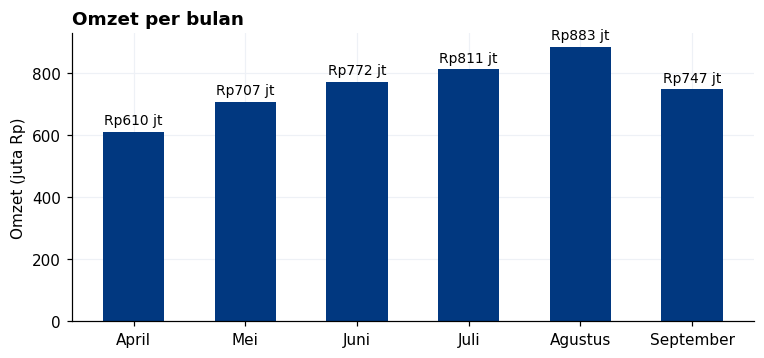

In [7]:
NAMA_BULAN = {4: 'April', 5: 'Mei', 6: 'Juni', 7: 'Juli', 8: 'Agustus', 9: 'September'}
bulanan = df.groupby('BULAN').agg(omzet=('JUMLAH', 'sum'), transaksi=('JUMLAH', 'size'),
                                  pelanggan=('PELANGGAN', 'nunique'))
bulanan['pertumbuhan_%'] = bulanan['omzet'].pct_change() * 100
bulanan.index = bulanan.index.map(NAMA_BULAN)
display(bulanan.style.format({'omzet': 'Rp{:,.0f}', 'transaksi': '{:,}', 'pertumbuhan_%': '{:+.1f}%'}, na_rep='—'))

fig, ax = plt.subplots(figsize=(8, 3.4))
bars = ax.bar(bulanan.index, bulanan['omzet'] / 1e6, color=BIRU, width=.55)
ax.bar_label(bars, labels=[f'Rp{v/1e6:,.0f} jt' for v in bulanan['omzet']], padding=3, fontsize=9)
ax.set_ylabel('Omzet (juta Rp)'); ax.set_title('Omzet per bulan', loc='left', fontweight='bold')
plt.show()

**Temuan:** omzet naik 4 bulan berturut-turut sampai puncaknya di Agustus, lalu turun di September.

## 6. Omzet per kategori

,omzet,porsi_%
KATEGORI,,
Olahan Ayam & Daging,"Rp1,597,044,250",35.3%
Olahan Ikan & Seafood,"Rp1,414,471,067",31.2%
Kentang Goreng,"Rp507,845,000",11.2%
Es Krim,"Rp439,914,500",9.7%
"Dimsum, Kulit & Camilan","Rp321,095,517",7.1%
"Keju, Saus & Lainnya","Rp249,960,286",5.5%


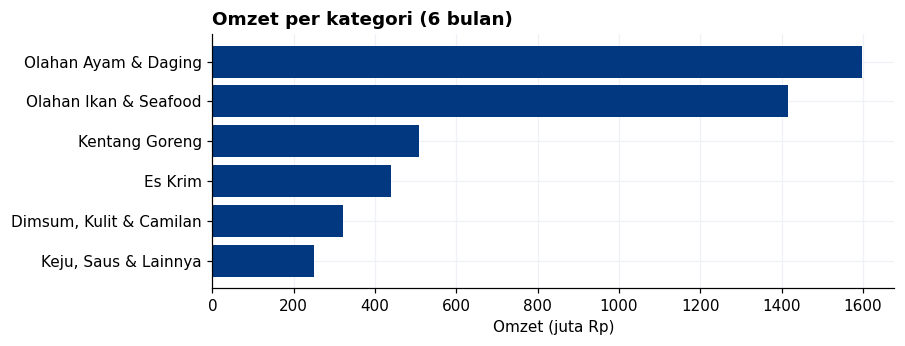

In [8]:
kat = df.groupby('KATEGORI')['JUMLAH'].sum().reindex(KATS).sort_values(ascending=False)
kat_tbl = pd.DataFrame({'omzet': kat, 'porsi_%': kat / kat.sum() * 100})
display(kat_tbl.style.format({'omzet': 'Rp{:,.0f}', 'porsi_%': '{:.1f}%'}))

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(kat.index[::-1], kat.values[::-1] / 1e6, color=BIRU)
ax.set_xlabel('Omzet (juta Rp)'); ax.set_title('Omzet per kategori (6 bulan)', loc='left', fontweight='bold')
plt.show()

## 7. Analisis Pareto (ABC) produk

Produk diurutkan dari omzet terbesar, lalu dihitung **persentase kumulatif** omzetnya.
Produk yang masuk sampai batas 80% omzet disebut **kelas A**: sedikit produk, tapi menyumbang sebagian besar uang masuk.

38 dari 268 produk (14%) menyumbang 80% omzet.


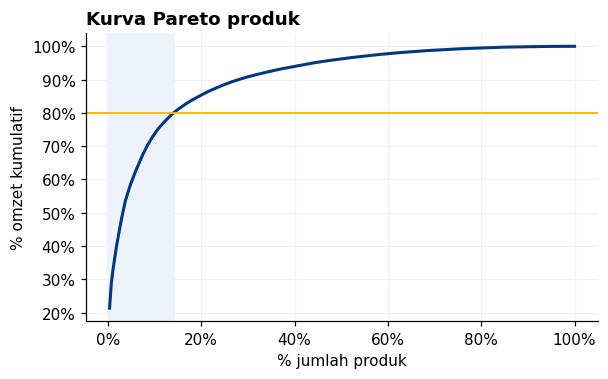

In [9]:
def pareto(d):
    p = d.groupby('KODEBARA')['JUMLAH'].sum().sort_values(ascending=False)
    p = p[p > 0]
    kum = (p.cumsum() / p.sum()).round(4)
    return {'n': len(p), 'k80': int((kum < 0.8).sum()) + 1, 'cum': kum.tolist()}

par = pareto(df)
print(f"{par['k80']} dari {par['n']} produk ({par['k80']/par['n']:.0%}) menyumbang 80% omzet.")

x = np.arange(1, par['n'] + 1) / par['n'] * 100
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.axvspan(0, par['k80'] / par['n'] * 100, color='#eef3fb')
ax.plot(x, np.array(par['cum']) * 100, color=BIRU, lw=2)
ax.axhline(80, color=KUNING, lw=1.2)
ax.set_xlabel('% jumlah produk'); ax.set_ylabel('% omzet kumulatif')
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Kurva Pareto produk', loc='left', fontweight='bold')
plt.show()

## 8. Pelanggan baru vs pelanggan lama

- **Pelanggan baru** pada bulan X = pelanggan yang pertama kali muncul di bulan X.
- **Pelanggan lama** = sudah pernah belanja di bulan sebelumnya.

Catatan: April adalah bulan pertama data, jadi semua pelanggan April otomatis terhitung "baru".

,pelanggan_lama,pelanggan_baru,omzet_lama,omzet_baru
BULAN,,,,
April,0,94,0,609614133
Mei,67,21,638734854,67983240
Juni,83,17,722134825,50103400
Juli,81,15,781920104,29439700
Agustus,90,22,641619440,241695500
September,81,14,650451814,96633610


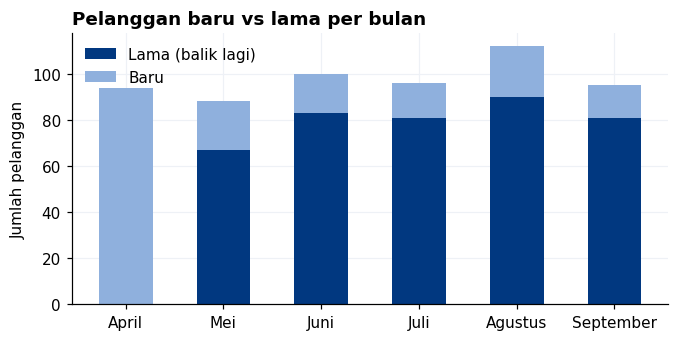

Sebaran: pelanggan belanja di berapa bulan (dari 6)?


,jumlah pelanggan
BULAN,
1,48
2,36
3,21
4,23
5,20
6,35


In [10]:
bulan_pertama = df.groupby('PELANGGAN')['BULAN'].min()
df['PELANGGAN_BARU'] = df['PELANGGAN'].map(bulan_pertama) == df['BULAN']
cohort = (df.groupby(['BULAN', 'PELANGGAN_BARU'])
            .agg(pelanggan=('PELANGGAN', 'nunique'), omzet=('JUMLAH', 'sum'))
            .unstack(fill_value=0))
cohort.columns = [f'{a}_{"baru" if b else "lama"}' for a, b in cohort.columns]
cohort.index = cohort.index.map(NAMA_BULAN)
display(cohort[['pelanggan_lama', 'pelanggan_baru', 'omzet_lama', 'omzet_baru']])

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(cohort.index, cohort['pelanggan_lama'], color=BIRU, label='Lama (balik lagi)', width=.55)
ax.bar(cohort.index, cohort['pelanggan_baru'], bottom=cohort['pelanggan_lama'], color=BIRU_MUDA, label='Baru', width=.55)
ax.set_ylabel('Jumlah pelanggan'); ax.legend(frameon=False)
ax.set_title('Pelanggan baru vs lama per bulan', loc='left', fontweight='bold')
plt.show()
print('Sebaran: pelanggan belanja di berapa bulan (dari 6)?')
display(bulan_aktif.value_counts().sort_index().rename('jumlah pelanggan').to_frame())

## 9. Pola hari dalam seminggu

In [11]:
HARI = ['Senin', 'Selasa', 'Rabu', 'Kamis', 'Jumat', 'Sabtu', 'Minggu']
def pola_hari(d):
    harian = d.groupby('TGL')['JUMLAH'].sum()
    g = harian.groupby(harian.index.dayofweek).agg(['mean', 'size'])
    return [{'h': HARI[i], 'avg': float(g.loc[i, 'mean']) if i in g.index else None,
             'n': int(g.loc[i, 'size']) if i in g.index else 0} for i in range(7)]

dow = pd.DataFrame(pola_hari(df)).set_index('h')
dow.columns = ['rata-rata omzet per hari buka', 'jumlah hari buka']
display(dow)

,rata-rata omzet per hari buka,jumlah hari buka
h,,
Senin,"37,701,678",21
Selasa,"25,310,633",24
Rabu,"39,405,100",26
Kamis,"24,184,383",23
Jumat,"38,412,734",23
Sabtu,"26,667,756",25
Minggu,"180,000",1


**Temuan:** Senin, Rabu, dan Jumat paling ramai. Hari Minggu praktis libur (hanya 1 hari ada transaksi selama 6 bulan).

## 10. Produk & pelanggan teratas

In [12]:
def nama_produk(raw):
    s = str(raw).upper()
    s = re.sub(r'\s*X\s*\d+\s*(PACK|PAK|PCS)?\s*$', '', s)   # buang keterangan isi dus di akhir
    s = s.title()
    s = re.sub(r'(\d)\.(\d)', r'\1,\2', s)
    s = re.sub(r'\b(Gr|Grm|Gram)\b', 'gr', s); s = re.sub(r'\bKg\b', 'kg', s); s = re.sub(r'\bLtr\b', 'L', s)
    return s.strip()

def top_produk(d, n=10):
    g = d.groupby('KODEBARA').agg(raw=('NAMABARA', 'first'), b=('MEREK', 'first'), o=('JUMLAH', 'sum'))
    g = g.sort_values('o', ascending=False).head(n)
    return [{'n': nama_produk(r.raw), 'raw': r.raw, 'b': r.b, 'o': int(r.o)} for r in g.itertuples()]

def top_pelanggan(d, n=10):
    g = d.groupby('PELANGGAN').agg(o=('JUMLAH', 'sum'), t=('JUMLAH', 'size')).sort_values('o', ascending=False).head(n)
    return [{'n': i, 'o': int(r.o), 't': int(r.t)} for i, r in g.iterrows()]

def top_merek(d, n=10):
    g = d.groupby('MEREK').agg(o=('JUMLAH', 'sum'), k=('KATEGORI', lambda s: s.mode()[0])).sort_values('o', ascending=False).head(n)
    return [{'n': i, 'k': KAT_PENDEK[r.k], 'o': int(r.o)} for i, r in g.iterrows()]

tp = pd.DataFrame(top_produk(df, 5)); tp['porsi_%'] = tp['o'] / k['omzet'] * 100
tc = pd.DataFrame(top_pelanggan(df, 10)); tc['porsi_%'] = tc['o'] / k['omzet'] * 100
print('5 produk paling laku'); display(tp[['n', 'b', 'o', 'porsi_%']])
print('5 pelanggan terbesar'); display(tc.head(5)[['n', 't', 'o', 'porsi_%']])
print(f"Porsi 5 pelanggan terbesar: {tc.head(5)['o'].sum()/k['omzet']:.1%} · 10 terbesar: {tc['o'].sum()/k['omzet']:.1%}")

5 produk paling laku


,n,b,o,porsi_%
0,Minaku Otak Otak 500 gr,Minaku,967688500,21
1,Okey Sosis 500 gr,Okey,336460000,7
2,"Lutosa Shoestring 2,5 kg",Lutosa,190984250,4
3,Jofrans Nugget Ayam Hati 500 gr,Jofrans,160543500,4
4,Okey Stick 500 gr,Okey,156563000,3


5 pelanggan terbesar


,n,t,o,porsi_%
0,Toko Cita Rasa Baru,528,547771782,12
1,Adek Frozen,286,420727170,9
2,Anton,145,311758150,7
3,Hite,83,229861080,5
4,Rumah Sosis,166,182693450,4


Porsi 5 pelanggan terbesar: 37.4% · 10 terbesar: 53.0%


## 11. Cek kejanggalan data

### 11a. Lonjakan penjualan harian (metode IQR)
Untuk setiap hari berjualan dihitung total omzetnya. Hari dianggap **tidak biasa** jika omzetnya di atas
**Q3 + 1,5 × IQR** (IQR = Q3 − Q1). Ini aturan pencilan (*outlier*) yang umum dipakai pada boxplot.

Q1 = Rp10,810,342 | Q3 = Rp42,675,820 | median = Rp20,628,000
Batas wajar = Rp90,474,036


,tanggal,omzet hari itu,pesanan terbesar,pelanggan,nilai pesanan,qty,satuan
0,2020-05-08,93943900,Minaku Otak Otak 500 Gr X 20 Pack,Firdon,10850000,35,DUS
1,2020-06-03,97545350,Minaku Otak Otak 500 Gr X 20 Pack,Adek Frozen,7750000,25,DUS
2,2020-06-26,188488506,Minaku Otak Otak 500 Gr X 20 Pack,Firdon,21700000,70,DUS
3,2020-07-29,163213698,Minaku Otak Otak 500 Gr X 20 Pack,Firdon,20150000,65,DUS
4,2020-08-03,129031800,Minaku Otak Otak 500 Gr X 20 Pack,Pak Sutarmuji,63200000,200,DUS
5,2020-08-18,144880990,Okey Sosis 1000 Gr X 10 Pack,Hite,13200000,40,DUS
6,2020-09-16,106766300,Minaku Otak Otak 500 Gr X 20 Pack,Firdon,9300000,30,DUS


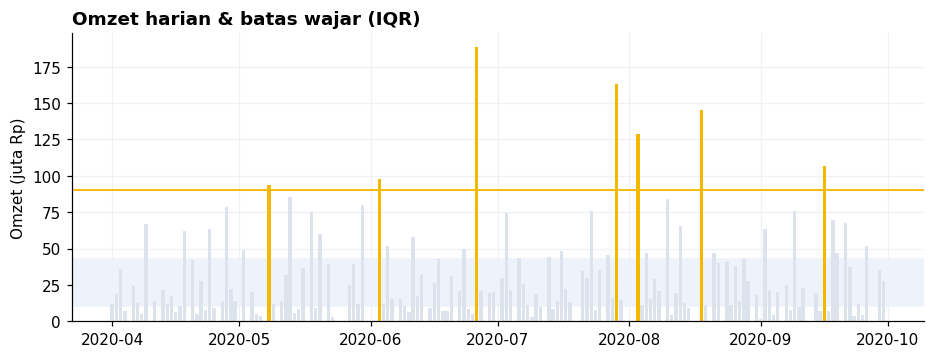

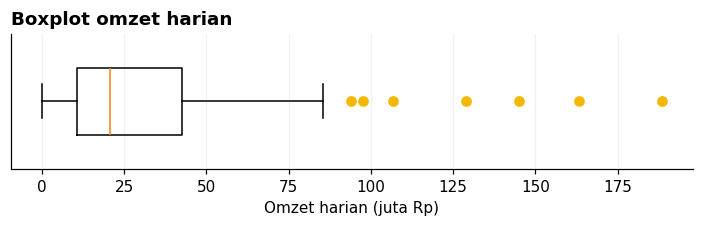

In [13]:
omzet_harian = df.groupby('TGL')['JUMLAH'].sum()
q1, q3 = omzet_harian.quantile([.25, .75])
batas = q3 + 1.5 * (q3 - q1)
print(f'Q1 = Rp{q1:,.0f} | Q3 = Rp{q3:,.0f} | median = Rp{omzet_harian.median():,.0f}')
print(f'Batas wajar = Rp{batas:,.0f}')

lonjakan = []
for tgl, v in omzet_harian[omzet_harian > batas].items():
    top = df[df['TGL'] == tgl].sort_values('JUMLAH', ascending=False).iloc[0]
    lonjakan.append({'t': tgl.strftime('%Y-%m-%d'), 'o': int(v), 'top': str(top['NAMABARA']).title(), 'tc': top['PELANGGAN'],
                     'tj': int(top['JUMLAH']), 'tq': int(top['QTY']), 'ts': top['SATUAN']})
display(pd.DataFrame(lonjakan).rename(columns={'t': 'tanggal', 'o': 'omzet hari itu', 'top': 'pesanan terbesar',
                                               'tc': 'pelanggan', 'tj': 'nilai pesanan', 'tq': 'qty', 'ts': 'satuan'}))

fig, ax = plt.subplots(figsize=(10, 3.4))
warna = [KUNING if v > batas else ABU for v in omzet_harian.values]
ax.bar(omzet_harian.index, omzet_harian.values / 1e6, color=warna, width=.8)
ax.axhline(batas / 1e6, color=KUNING, lw=1.2); ax.axhspan(q1 / 1e6, q3 / 1e6, color='#eef3fb', zorder=0)
ax.set_ylabel('Omzet (juta Rp)'); ax.set_title('Omzet harian & batas wajar (IQR)', loc='left', fontweight='bold')
plt.show()

fig, ax = plt.subplots(figsize=(8, 1.6))
ax.boxplot(omzet_harian / 1e6, vert=False, widths=.5, flierprops={'markerfacecolor': KUNING, 'markeredgecolor': KUNING})
ax.set_yticks([]); ax.set_xlabel('Omzet harian (juta Rp)'); ax.set_title('Boxplot omzet harian', loc='left', fontweight='bold')
plt.show()

### 11b. Barang keluar dengan harga Rp0
Baris dengan `HARGA` = 0 (dan `JUMLAH` = 0). Untuk memperkirakan nilainya, setiap baris dikalikan dengan
**harga median** produk & satuan yang sama dari transaksi lain.

In [14]:
harga_median = df[df['HARGA'] > 0].groupby(['KODEBARA', 'SATUAN'])['HARGA'].median().rename('harga_median')
df = df.drop(columns='harga_median', errors='ignore').join(harga_median, on=['KODEBARA', 'SATUAN'])

nol = df[df['HARGA'] <= 0].copy()
nol['perkiraan_nilai'] = (nol['QTY'] * nol['harga_median']).fillna(0)
nol['keterangan'] = np.where(nol['PELANGGAN'].str.contains('Samp'), 'Sampel/promo',
                     np.where(nol['PELANGGAN'] == 'Cash', 'Penjualan tunai tanpa harga', 'Tanpa harga'))
print(f'{len(nol)} baris, perkiraan nilai barang Rp{nol["perkiraan_nilai"].sum():,.0f}')
display(nol.groupby('keterangan').agg(baris=('QTY', 'size'), perkiraan_nilai=('perkiraan_nilai', 'sum')))
nol.sort_values('perkiraan_nilai', ascending=False)[['TGL', 'NAMABARA', 'PELANGGAN', 'QTY', 'SATUAN', 'HARGA', 'JUMLAH', 'perkiraan_nilai']].head(10)

58 baris, perkiraan nilai barang Rp91,793,050


,baris,perkiraan_nilai
keterangan,,
Penjualan tunai tanpa harga,20,"91,082,700"
Sampel/promo,12,"331,100"
Tanpa harga,26,"379,250"


,TGL,NAMABARA,PELANGGAN,QTY,SATUAN,HARGA,JUMLAH,perkiraan_nilai
858,2020-04-25,LUTOSA SHOESTRING 2.5 KG X 4 PACK,Cash,106,DUS,0,0,"25,440,000"
2289,2020-06-08,ARTHUR SHOESTRING 2.5 KG X 4 PACK,Cash,75,DUS,0,0,"18,375,000"
2292,2020-06-08,LUTOSA SHOESTRING 2.5 KG X 4 PACK,Cash,52,DUS,0,0,"12,480,000"
2011,2020-05-30,JULIENNE SHOESTRING 2.5 KG X 4 PACK,Cash,43,DUS,0,0,"10,320,000"
3308,2020-07-04,CAVENDISH SHOESTRING 2.94 KG X 6 PACK,Cash,16,DUS,0,0,"7,056,000"
3307,2020-07-04,LUTOSA SHOESTRING 2.5 KG X 4 PACK,Cash,20,DUS,0,0,"4,800,000"
1154,2020-05-04,LUTOSA SHOESTRING 2.5 KG X 4 PACK,Cash,13,DUS,0,0,"3,120,000"
4689,2020-08-06,CAVENDISH SHOESTRING 2.94 KG X 6 PACK,Cash,6,DUS,0,0,"2,646,000"
3309,2020-07-04,STAR JULIENNE SHOESTRING 2.5 KG X 5 PACK,Cash,5,DUS,0,0,"1,500,000"
2290,2020-06-08,AVIKO SHOESTRING 2.5 KG X 4 PACK,Cash,7,DUS,0,0,"1,470,000"


### 11c. JUMLAH tidak sama dengan QTY × HARGA

In [15]:
df['SELISIH'] = df['QTY'] * df['HARGA'] - df['JUMLAH']
selisih = df[(df['SELISIH'].abs() > 1) & (df['HARGA'] > 0)].copy()
selisih['potongan_%'] = (selisih['SELISIH'] / (selisih['QTY'] * selisih['HARGA']) * 100).round()
print(f'{len(selisih)} baris, total selisih Rp{selisih["SELISIH"].sum():,.0f}')
print('Sebaran besar potongan (%):'); display(selisih['potongan_%'].describe().to_frame().T)
selisih.sort_values('SELISIH', ascending=False)[['TGL', 'NAMABARA', 'PELANGGAN', 'QTY', 'HARGA', 'JUMLAH', 'SELISIH', 'potongan_%']].head(10)

77 baris, total selisih Rp4,436,797
Sebaran besar potongan (%):


,count,mean,std,min,25%,50%,75%,max
potongan_%,77,9,10,3,4,8,8,50


,TGL,NAMABARA,PELANGGAN,QTY,HARGA,JUMLAH,SELISIH,potongan_%
4557,2020-08-03,MITRAKU CHILI&CELERY FISHCAKE 500GR X 20,Pak Erwin,27,28900,390150,390150,50
393,2020-04-11,MITRAKU FISH CAKE SINGAPORE 1000 GR X 10,Pak Supri,5,520000,2340000,260000,10
4558,2020-08-03,MITRAKU SCALLOP 200 GR X 40 PACK,Pak Erwin,51,9900,252450,252450,50
2178,2020-06-05,OKEY STICK 500 GR X 10 PACK,Hite,40,185000,7200000,200000,3
3667,2020-07-13,BF HAKAU UDANG 222 GR X 32 PACK,Anton,2,875200,1575360,175040,10
823,2020-04-24,BF DIMSUM SIOMAY REG-NEW 200 GR X 48 PAK,Adek Frozen,2,825600,1486080,165120,10
2323,2020-06-09,MITRAKU CHILI&CELERY FISHCAKE 500GR X 20,Pak Erwin,10,28900,144500,144500,50
670,2020-04-20,OKEY STICK 500 GR X 10 PACK,Hite,25,185000,4500000,125000,3
1728,2020-05-22,OKEY STICK 500 GR X 10 PACK,Hite,20,185000,3600000,100000,3
6702,2020-09-29,OKEY STICK 500 GR X 10 PACK,Hite,20,185000,3600000,100000,3


## 12. Ekspor hasil ke dashboard

Semua hasil di atas dikumpulkan menjadi satu data JSON, lalu **ditulis langsung ke file HTML dashboard**
(menggantikan baris `const DATA`, `const EXTRA`, dan `const ANOM`). Jadi angka yang tampil di dashboard = angka dari notebook ini.

In [16]:
def slice_data(d):
    kat_o = d.groupby('KATEGORI')['JUMLAH'].sum()
    return {'kpi': kpi(d),
            'kat': [{'k': c, 's': KAT_PENDEK[c], 'o': int(kat_o.get(c, 0))} for c in KATS],
            'produk': top_produk(d), 'merek': top_merek(d), 'pelanggan': top_pelanggan(d), 'dow': pola_hari(d)}

slices = {'all': slice_data(df)}
for b in range(4, 10):
    slices[str(b)] = slice_data(df[df['BULAN'] == b])

kalender = pd.date_range('2020-04-01', '2020-09-30')
hr = df.groupby('TGL').agg(o=('JUMLAH', 'sum'), n=('JUMLAH', 'size')).reindex(kalender, fill_value=0)
harian = [{'t': t.strftime('%Y-%m-%d'), 'o': int(r.o), 'n': int(r.n), 'w': int((t.dayofweek + 1) % 7)} for t, r in hr.iterrows()]

DATA = {'slices': slices,
        'bulan': [{'m': b, 'l': NAMA_BULAN[b][:3], 'f': NAMA_BULAN[b]} for b in range(4, 10)],
        'harian': harian,
        'kat_bulan': {c: [int(df[(df['KATEGORI'] == c) & (df['BULAN'] == b)]['JUMLAH'].sum()) for b in range(4, 10)] for c in KATS},
        'kats': [{'k': c, 's': KAT_PENDEK[c]} for c in KATS],
        'total_all': k['omzet'], 'aktif6': aktif6}

EXTRA = {'pareto': {'all': pareto(df), **{str(b): pareto(df[df['BULAN'] == b]) for b in range(4, 10)}},
         'cohort': [{'m': b,
                     'baru': int(df[(df['BULAN'] == b) & df['PELANGGAN_BARU']]['PELANGGAN'].nunique()),
                     'lama': int(df[(df['BULAN'] == b) & ~df['PELANGGAN_BARU']]['PELANGGAN'].nunique()),
                     'ob': int(df[(df['BULAN'] == b) & df['PELANGGAN_BARU']]['JUMLAH'].sum()),
                     'ol': int(df[(df['BULAN'] == b) & ~df['PELANGGAN_BARU']]['JUMLAH'].sum())} for b in range(4, 10)]}

def baris_anom(r, ket, nilai):
    return {'t': r.TGL.strftime('%Y-%m-%d'), 'm': int(r.BULAN), 'b': str(r.NAMABARA).title(), 'c': r.PELANGGAN,
            'q': int(r.QTY), 's': r.SATUAN, 'h': int(r.HARGA), 'j': int(r.JUMLAH), 'k': ket, 'x': int(nilai)}

ANOM = {'anom': {'nol': [baris_anom(r, r.keterangan, r.perkiraan_nilai) for r in nol.itertuples()],
                 'selisih': [baris_anom(r, f'Potongan {int(round(r.SELISIH / (r.QTY * r.HARGA) * 100))}%', r.SELISIH)
                             for r in selisih.itertuples()]},
        'batas': float(batas), 'q1': float(q1), 'q3': float(q3), 'median': float(omzet_harian.median()),
        'lonjakan': lonjakan}

def to_js(name, obj):
    return f'const {name} = ' + json.dumps(obj, ensure_ascii=False, separators=(',', ':')) + ';'

html = DASHBOARD.read_text(encoding='utf-8').split('\n')
for i, line in enumerate(html):
    for name, obj in [('DATA', DATA), ('EXTRA', EXTRA), ('ANOM', ANOM)]:
        if line.startswith(f'const {name} = '):
            html[i] = to_js(name, obj)
DASHBOARD.write_text('\n'.join(html), encoding='utf-8')
print('✔ Dashboard diperbarui:', DASHBOARD)

✔ Dashboard diperbarui: Dashboard Visualisasi\Dashboard Visualisasi\Dashboard 1 - Ringkasan Eksekutif (Simple).html


## 13. Ringkasan: angka di notebook = angka di dashboard

In [17]:
# Baca ulang data yang sekarang tertanam di dashboard, lalu bandingkan dengan hasil notebook
teks = DASHBOARD.read_text(encoding='utf-8')
ambil = lambda name: json.loads(re.search(rf'^const {name} = (.*);$', teks, re.M).group(1))
D_dash, E_dash, A_dash = ambil('DATA'), ambil('EXTRA'), ambil('ANOM')
kd = D_dash['slices']['all']['kpi']
ringkas = pd.DataFrame([
    ('Total omzet', k['omzet'], kd['omzet']),
    ('Transaksi', k['trx'], kd['trx']),
    ('Pelanggan', k['pelanggan'], kd['pelanggan']),
    ('Rata-rata per transaksi', round(k['rata_trx']), round(kd['rata_trx'])),
    ('Produk kelas A (80% omzet)', par['k80'], E_dash['pareto']['all']['k80']),
    ('Hari lonjakan (IQR)', len(lonjakan), len(A_dash['lonjakan'])),
    ('Baris harga Rp0', len(nol), len(A_dash['anom']['nol'])),
    ('Baris JUMLAH ≠ QTY×HARGA', len(selisih), len(A_dash['anom']['selisih'])),
], columns=['Indikator', 'Hasil notebook', 'Di dashboard'])
ringkas['Sama?'] = ringkas['Hasil notebook'] == ringkas['Di dashboard']
display(ringkas)
assert ringkas['Sama?'].all()
print('✔ Semua angka dashboard berasal dari notebook ini.')

,Indikator,Hasil notebook,Di dashboard,Sama?
0,Total omzet,4530330620,4530330620,True
1,Transaksi,6778,6778,True
2,Pelanggan,183,183,True
3,Rata-rata per transaksi,668388,668388,True
4,Produk kelas A (80% omzet),38,38,True
5,Hari lonjakan (IQR),7,7,True
6,Baris harga Rp0,58,58,True
7,Baris JUMLAH ≠ QTY×HARGA,77,77,True


✔ Semua angka dashboard berasal dari notebook ini.
